# Подготовка признаков и обучение моделей

Используем очищенную выборку из EDA. Целевая переменная —
`asking_price_per_m2_rub`, цена предложения за м² в рублях.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    GroupShuffleSplit, train_test_split, GroupKFold, cross_val_score
)
from sklearn.metrics import mean_absolute_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from catboost import CatBoostRegressor, Pool, cv

import matplotlib.pyplot as plt
import seaborn as sns

import optuna

import shap

/Users/mishamishin/Desktop/DataScience/Тестовое/newbuild-price-estimator/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

data_dir = Path("data") if Path("data").is_dir() else Path("../data")
df = pd.read_csv(data_dir / "processed" / "newbuild_prices_clean.csv")

## 1. Разбиение на обучение и тест

Сравним два сценария: случайный тест из 20% объявлений и групповой
тест из 30% ЖК. Во втором сценарии модель проверяется на комплексах,
которых не видела при обучении. Доля строк в таком тесте может
отличаться от 30%, потому что в ЖК разное число объявлений.

Используем одни и те же разбиения для всех моделей. Тестовые данные
не участвуют в выборе признаков и гиперпараметров.

In [3]:
# Случайное разбиение
random_train, random_test = train_test_split(
    df, test_size=0.2, random_state=SEED
)

# Групповое разбиение
splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, groups=df["project_group"]))

group_train = df.iloc[train_idx]
group_test = df.iloc[test_idx]

In [4]:
rows = []

for name, train, test in [
    ("Случайное", random_train, random_test),
    ("Групповое", group_train, group_test),
]:
    train_projects = set(train["project_group"])
    test_projects = set(test["project_group"])

    rows.append({
        "Разбиение": name,
        "Строк в train": len(train),
        "Строк в test": len(test),
        "ЖК в test": len(test_projects),
        "Общих ЖК": len(train_projects & test_projects),
    })

pd.DataFrame(rows)

,Разбиение,Строк в train,Строк в test,ЖК в test,Общих ЖК
0,Случайное,674,169,32,30
1,Групповое,716,127,13,0


В тест разбиения по группам попали 13 ЖК и 127 объявлений - около 15% строк. Пересечений ЖК с обучением нет.  
В случайном тесте 169 объявлений, и 30 ЖК встречаются в обеих частях - это как раз различие между сценариями, которое нам нужно.

## 2. Подготовка признаков

Базовый набор: застройщик, комнатность, площадь и этаж.
В расширенный набор добавляем отделку и относительный этаж —
отношение этажа квартиры к этажности дома. Если этажность
неизвестна, относительный этаж остаётся пропуском.

Цены, скидки, идентификаторы и название ЖК не используем
как признаки. `project_group` нужен для разбиения.

In [5]:
TARGET = "asking_price_per_m2_rub"

base_features = ["developer", "rooms", "area_m2", "floor"]
extended_features = base_features + ["finish", "relative_floor"]

group_train = group_train.assign(
    relative_floor=group_train["floor"] / group_train["floors_total"]
)

### 2.1. Связи между числовыми признаками

На обучающей части группового разбиения смотрим корреляции Пирсона
между числовыми признаками и ценой за м². Застройщика и отделку
не кодируем числами ради этой матрицы. Для каждой пары используем
строки, где известны оба значения.

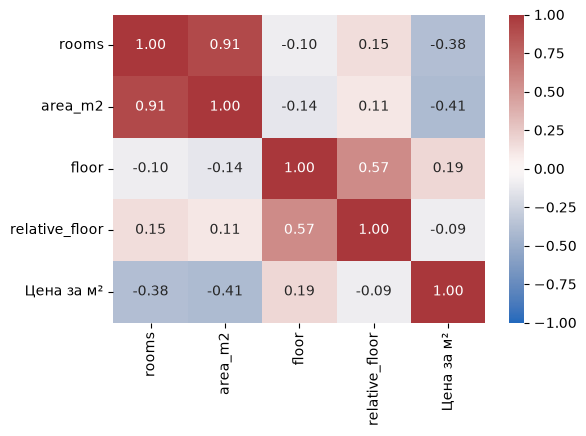

In [6]:
columns = ["rooms", "area_m2", "floor", "relative_floor", TARGET]
corr = group_train[columns].rename(columns={TARGET: "Цена за м²"}).corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.show()

Площадь и комнатность тесно связаны между собой (`r = 0.91`).
Связь с ценой за м² у обоих признаков отрицательная
(`−0.41` для площади, `−0.38` для комнатности).
Для этажа линейная связь слабее (`0.19`).

Посмотрим на диаграммах рассеяния, как меняется цена за м²
с площадью и этажом и различается ли картина по застройщикам.

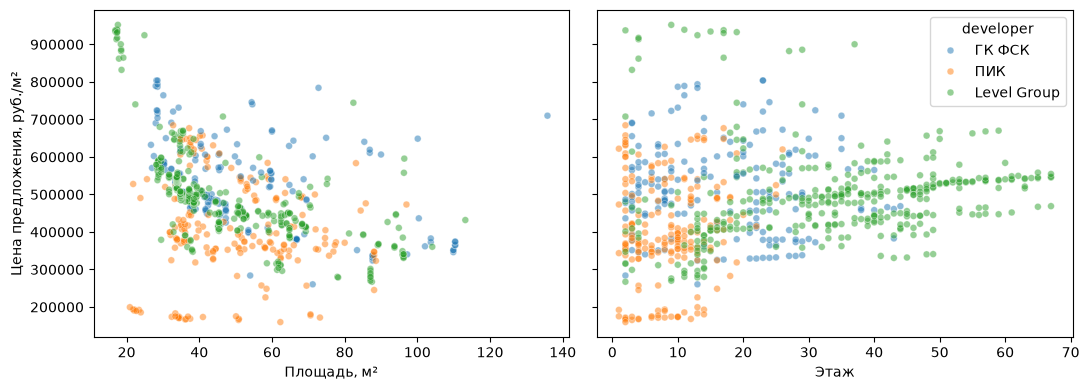

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for i, (feature, label) in enumerate([
    ("area_m2", "Площадь, м²"),
    ("floor", "Этаж"),
]):
    sns.scatterplot(
        data=group_train, x=feature, y=TARGET,
        hue="developer", alpha=0.5, s=24,
        legend=(i == 1), ax=axes[i],
    )
    axes[i].set_xlabel(label)

axes[0].set_ylabel("Цена предложения, руб./м²")
plt.tight_layout()
plt.show()

Цена за м² в целом снижается с ростом площади, причём у небольших
квартир спад выглядит резче. Можно проверить, улучшает ли замена площади
на её логарифм качество `Ridge`.

## 3. Медианный baseline

Для квартиры прогнозируем медианную цену за м² среди объявлений
с тем же застройщиком и комнатностью. Если такой пары в обучении
нет, используем общую медиану.

Оцениваем baseline на пяти фолдах по ЖК внутри групповой обучающей
части. На каждом фолде считаем медианы только по его обучающим
строкам. Метрика — `MAE` в руб./м².

In [8]:
# Baseline
def predict_baseline(train, validation):
    keys = ["developer", "rooms"]
    medians = train.groupby(keys)[TARGET].median()

    predictions = validation.join(medians.rename("prediction"), on=keys)
    return predictions["prediction"].fillna(train[TARGET].median())

In [9]:
# Фиксируем фолды для сравнения моделей
group_folds = list(
    GroupKFold(n_splits=5).split(group_train, groups=group_train["project_group"])
)

In [10]:
scores = []

for train_idx, val_idx in group_folds:
    train = group_train.iloc[train_idx]
    validation = group_train.iloc[val_idx]

    predictions = predict_baseline(train, validation)
    scores.append(mean_absolute_error(validation[TARGET], predictions))

baseline_mae = pd.DataFrame({"Фолд": range(1, 6), "MAE, руб./м²": scores})
print(baseline_mae.round().to_string(index=False))
print(f"Средний MAE: {baseline_mae["MAE, руб./м²"].mean():,.0f} руб./м²")

 Фолд  MAE, руб./м²
    1       75304.0
    2      176309.0
    3      164785.0
    4      112751.0
    5      139975.0
Средний MAE: 133,825 руб./м²


## 4. Ridge

Числовые признаки масштабируем, застройщика и отделку кодируем
через one-hot. Предобработка обучается отдельно на каждом фолде.
Во всех экспериментах используем те же пять групповых фолдов,
что и для baseline, и фиксируем `alpha=1.0`.

### 4.1. Исходная площадь и `log1p`

На базовом наборе сравниваем исходную площадь и `log1p(area_m2)`.
Остальные признаки не меняем.

In [11]:
preprocessing = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     ["rooms", "area_m2", "floor"]),
    ("developer", OneHotEncoder(handle_unknown="ignore"), ["developer"]),
])

ridge = make_pipeline(preprocessing, Ridge(alpha=1.0))

In [12]:
X = group_train[base_features]
y = group_train[TARGET]

ridge_inputs = {
    "Ridge: площадь": X,
    "Ridge: лог площади": X.assign(area_m2=np.log1p(X["area_m2"])),
}

In [13]:
comparison = baseline_mae.rename(columns={"MAE, руб./м²": "Baseline"}).copy()
comparison = comparison.set_index("Фолд")

for name, features in ridge_inputs.items():
    comparison[name] = -cross_val_score(
        ridge, features, y, cv=group_folds,
        scoring="neg_mean_absolute_error",
    )

comparison.loc["Среднее"] = comparison.mean()
comparison.round().astype(int)

,Baseline,Ridge: площадь,Ridge: лог площади
Фолд,,,
1,75304,93389,72630
2,176309,167490,164122
3,164785,172705,172111
4,112751,108455,111408
5,139975,157345,163206
Среднее,133825,139877,136695


`log1p` снизил средний MAE с 139 877 до 136 695 руб./м².
Улучшение есть на трёх из пяти фолдов, причём самое большое -
на первом. Для следующего сравнения фиксируем `log1p`.

### 4.2. Базовый и расширенный наборы признаков

Проверяем, снижают ли MAE отделка и относительный этаж.
Преобразование площади и параметры `Ridge` не меняем.

In [14]:
def build_ridge(features):
    categorical = [col for col in ["developer", "finish"] if col in features]
    numeric = [col for col in features if col not in categorical]

    preprocessing = ColumnTransformer([
        ("numeric", make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler()
        ), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

    return make_pipeline(preprocessing, Ridge(alpha=1.0))

In [15]:
ridge_data = group_train[extended_features].assign(
    area_m2=lambda data: np.log1p(data["area_m2"])
)

feature_sets = {
    "Ridge: базовый": base_features,
    "Ridge: расширенный": extended_features,
}

In [16]:
ridge_comparison = (
    baseline_mae.set_index("Фолд")
    .rename(columns={"MAE, руб./м²": "Baseline"})
)

for name, features in feature_sets.items():
    ridge_comparison[name] = -cross_val_score(
        build_ridge(features),
        ridge_data[features],
        group_train[TARGET],
        cv=group_folds,
        scoring="neg_mean_absolute_error",
    )

ridge_comparison.loc["Среднее"] = ridge_comparison.mean()
ridge_comparison.round().astype(int)

,Baseline,Ridge: базовый,Ridge: расширенный
Фолд,,,
1,75304,72630,86114
2,176309,164122,165943
3,164785,172111,169063
4,112751,111408,113328
5,139975,163206,168327
Среднее,133825,136695,140555


Расширенный набор увеличил средний MAE с 136 695 до
140 555 руб./м² и улучшил результат только на одном из пяти фолдов.
Для `Ridge` оставляем базовый набор с `log1p(area_m2)`.
На групповой валидации медианный `baseline` пока лучше обоих
вариантов Ridge: 133 825 руб./м².

## 5. CatBoost

### 5.1. Базовый и расширенный наборы признаков

Сравниваем наборы на тех же групповых фолдах, что и Ridge.
Параметры CatBoost одинаковы. Застройщика и отделку передаём
как категории. Пропуск отделки обозначаем как «Не указано»,
а пропуски числовых признаков оставляем без заполнения.

In [17]:
cat_data = group_train[extended_features].copy()
cat_data["finish"] = cat_data["finish"].fillna("Не указано")

In [18]:
catboost_mae = pd.DataFrame(index=baseline_mae["Фолд"])

for name, features in {
    "CatBoost: базовый": base_features,
    "CatBoost: расширенный": extended_features,
}.items():
    model = CatBoostRegressor(
        iterations=500, depth=6, learning_rate=0.05,
        loss_function="MAE", random_seed=SEED,
        verbose=False, allow_writing_files=False,
    )

    categorical = [col for col in ["developer", "finish"] if col in features]
    catboost_mae[name] = -cross_val_score(
        model, cat_data[features], group_train[TARGET],
        cv=group_folds, scoring="neg_mean_absolute_error",
        params={"cat_features": categorical}
    )

In [19]:
catboost_mae.loc["Среднее"] = catboost_mae.mean()
final_sets_comparison = pd.concat([
    ridge_comparison,
    catboost_mae
], axis=1).round().astype(int)

final_sets_comparison

,Baseline,Ridge: базовый,Ridge: расширенный,CatBoost: базовый,CatBoost: расширенный
Фолд,,,,,
1,75304,72630,86114,88434,116713
2,176309,164122,165943,174558,194862
3,164785,172111,169063,156788,160809
4,112751,111408,113328,132188,144164
5,139975,163206,168327,169637,161976
Среднее,133825,136695,140555,144321,155705


### 5.2. Подбор гиперпараметров CatBoost

На базовом наборе признаков подбираем глубину деревьев, скорость
обучения и число итераций. Optuna выполнит 20 попыток.
Критерий выбора — средний MAE на тех же пяти групповых фолдах.

In [20]:
cat_pool = Pool(
    cat_data[base_features],
    label=group_train[TARGET],
    cat_features=["developer"],
)

In [21]:
def objective(trial):
    params = {
        "depth": trial.suggest_int("depth", 3, 7),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "iterations": 300,
        "loss_function": "MAE",
        "random_seed": SEED,
        "allow_writing_files": False,
        "verbose": False,
    }

    history = cv(
        cat_pool, params, folds=group_folds,
        early_stopping_rounds=30, logging_level='Silent'
    )
    best = history.loc[history["test-MAE-mean"].idxmin()]

    trial.set_user_attr("iterations", int(best["iterations"]) + 1)
    return float(best["test-MAE-mean"])

In [22]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=20)

In [23]:
best_params = {
    **study.best_params,
    "iterations": study.best_trial.user_attrs["iterations"],
}

print("Лучшие параметры:", best_params)
print(f"До подбора:    {catboost_mae.loc['Среднее', 'CatBoost: базовый']:,.0f} руб./м²")
print(f"После подбора: {study.best_value:,.0f} руб./м²")

Лучшие параметры: {'depth': 3, 'learning_rate': 0.18661212048851333, 'iterations': 15}
До подбора:    144,321 руб./м²
После подбора: 109,051 руб./м²


Фиксируем CatBoost на базовом наборе:
- `depth`=3
- `learning_rate`=0.18661212048851333
- `iterations`=15

После подбора средний MAE на групповых фолдах снизился с 144 321 до 109 051 руб./м² — примерно на 24%. Это лучший результат на валидации.

## 6. Итоги групповой валидации

Сравниваем медианный `baseline`, лучший вариант `Ridge` и `CatBoost`
после подбора параметров. Все результаты получены на одних и тех же
пяти групповых фолдах внутри обучающей части.

In [24]:
validation_summary = pd.DataFrame({
    "Модель": ["Baseline", "Ridge: базовый + log1p", "CatBoost: базовый, после подбора"],
    "Средний MAE, руб./м²": [
        baseline_mae["MAE, руб./м²"].mean(),
        ridge_comparison.loc["Среднее", "Ridge: базовый"],
        study.best_value,
    ],
})

validation_summary.round({"Средний MAE, руб./м²": 0})

,Модель,"Средний MAE, руб./м²"
0,Baseline,133825.0
1,Ridge: базовый + log1p,136695.0
2,"CatBoost: базовый, после подбора",109051.0


Для итоговой модели выбираем `CatBoost` на базовом наборе признаков.
Фиксируем параметры до оценки на отложенных тестах.

## 7. Оценка на отложенных тестах

Сравниваем модели на случайном и групповом тестах.
Для каждого разбиения обучаем модели заново на его обучающей части,
не меняя признаки и параметры.

MAE — средняя абсолютная ошибка в руб./м².
MedAPE — медианная абсолютная ошибка в процентах от фактической цены.

In [25]:
def predict_models(train, test):
    X_train = train[base_features]
    X_test = test[base_features]
    y_train = train[TARGET]

    ridge = build_ridge(base_features)
    ridge.fit(X_train.assign(area_m2=np.log1p(X_train["area_m2"])), y_train)
    ridge_pred = ridge.predict(
        X_test.assign(area_m2=np.log1p(X_test["area_m2"]))
    )

    catboost = CatBoostRegressor(
        **best_params,
        loss_function="MAE", random_seed=SEED,
        verbose=False, allow_writing_files=False,
    )
    catboost.fit(X_train, y_train, cat_features=["developer"])

    predictions = {
        "Baseline": predict_baseline(train, test),
        "Ridge": ridge_pred,
        "CatBoost": catboost.predict(X_test),
    }

    # Сохраним catboost для SHAP
    return predictions, catboost

In [26]:
# Получаем прогнозы на обоих тестах
random_predictions, _ = predict_models(random_train, random_test)
group_predictions, group_catboost = predict_models(group_train, group_test)

test_predictions = {
    "Случайное": random_predictions,
    "Групповое": group_predictions,
}

# Считаем метрики
rows = []

for split, test in [("Случайное", random_test), ("Групповое", group_test)]:
    actual = test[TARGET].to_numpy()

    for model, prediction in test_predictions[split].items():
        rows.append({
            "Разбиение": split,
            "Модель": model,
            "MAE, руб./м²": mean_absolute_error(actual, prediction),
            "MedAPE, %": 100 * np.median(np.abs(actual - prediction) / actual),
        })

test_metrics = pd.DataFrame(rows)
test_metrics.round({"MAE, руб./м²": 0, "MedAPE, %": 1})

,Разбиение,Модель,"MAE, руб./м²","MedAPE, %"
0,Случайное,Baseline,86136.0,11.1
1,Случайное,Ridge,89582.0,13.0
2,Случайное,CatBoost,89093.0,12.6
3,Групповое,Baseline,150755.0,28.0
4,Групповое,Ridge,158532.0,27.5
5,Групповое,CatBoost,165286.0,31.7


На групповом тесте MAE вырос у всех моделей. Это согласуется
с тем, что прогноз на незнакомых ЖК сложнее, но тестовые выборки
также различаются по составу, поэтому весь рост ошибки нельзя
приписать только способу разбиения.

Baseline показал наименьший MAE на обоих тестах. CatBoost,
выбранный до просмотра тестов по групповой валидации,
не подтвердил своё преимущество на отложенных ЖК.

### 7.1. Ошибки на новых ЖК

Разберём ошибки CatBoost по застройщикам, комнатности и диапазонам
фактической цены. Для каждого сегмента укажем число объявлений.

In [27]:
# Сохраняем прогнозы и ошибки на уровне объявления
group_results = group_test.assign(
    prediction=test_predictions["Групповое"]["CatBoost"]
)
group_results["absolute_error"] = (
    group_results[TARGET] - group_results["prediction"]
).abs()
group_results["ape"] = 100 * group_results["absolute_error"] / group_results[TARGET]

# Выделяем три диапазона фактической цены
group_results["price_band"] = pd.qcut(group_results[TARGET], q=3).astype(str)

for column, label in [
    ("developer", "Застройщик"),
    ("rooms", "Комнатность"),
    ("price_band", "Цена за м², руб."),
]:
    summary = group_results.groupby(column).agg(
        объявлений=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        MedAPE=("ape", "median"),
    )
    display(summary.rename_axis(label).round({"MAE": 0, "MedAPE": 1}))

,объявлений,MAE,MedAPE
Застройщик,,,
Level Group,53,151357.0,29.2
ГК ФСК,52,174779.0,32.7
ПИК,22,176403.0,64.9


,объявлений,MAE,MedAPE
Комнатность,,,
0,7,209463.0,41.8
1,31,167197.0,34.5
2,57,167054.0,30.7
3,30,143050.0,25.2
4,2,264185.0,40.2


,объявлений,MAE,MedAPE
"Цена за м², руб.",,,
"(213199.999, 460484.0]",43,155688.0,62.1
"(460484.0, 580400.0]",42,121128.0,23.5
"(580400.0, 856290.0]",42,219271.0,32.2


У ПИК самая высокая относительная ошибка: MedAPE 64,9% на 22
объявлениях. По MAE самый сложный ценовой сегмент — верхний:
219 271 руб./м² на 42 объявлениях. По MedAPE, наоборот, выделяется
нижний сегмент: 62,1% на 43 объявлениях.

Среди групп по комнатности самый высокий MAE у четырёхкомнатных
квартир, но в тесте их всего две. Среди групп хотя бы с пятью
объявлениями самый высокий MAE у студий: 209 463 руб./м² (7 объявлений).

### 7.2. Фактическая и прогнозная цена

Сравниваем прогнозы CatBoost с фактической ценой предложения
на новых ЖК. Пунктир - линия точного прогноза: выше неё модель
завышает цену относительно факта, ниже - занижает.

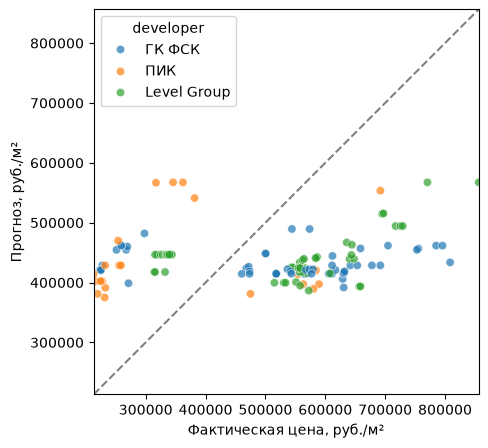

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.scatterplot(
    data=group_results, x=TARGET, y="prediction",
    hue="developer", alpha=0.7, ax=ax,
)

low = group_results[[TARGET, "prediction"]].min().min()
high = group_results[[TARGET, "prediction"]].max().max()
ax.plot([low, high], [low, high], "--", color="gray")

ax.set(
    xlabel="Фактическая цена, руб./м²",
    ylabel="Прогноз, руб./м²",
    xlim=(low, high),
    ylim=(low, high),
    aspect="equal",
)
plt.show()

На групповом тесте прогнозы лежат примерно в диапазоне
370-570 тыс. руб./м², тогда как фактические цены — 200–850 тыс. руб./м².
В нижней части ценового диапазона модель чаще завышает цену,
а в верхней — занижает. Это объясняет направление ошибок,
которое не видно из MAE и MedAPE.

### 7.3. Важность признаков

Оценим, насколько меняется MAE на групповом тесте, если перемешать
значения одного признака, оставив остальные без изменений. Повторим
перемешивание 20 раз для каждого признака. Модель не переобучаем.

In [29]:
X_group = group_test[base_features]
y_group = group_test[TARGET]

perm = permutation_importance(
    group_catboost,
    X_group,
    y_group,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
)

pd.DataFrame(
    {
        "Среднее изменение MAE, руб./м²": perm.importances_mean,
        "Стандартное отклонение, руб./м²": perm.importances_std,
    },
    index=X_group.columns,
).sort_values("Среднее изменение MAE, руб./м²", ascending=False).round(0)

,"Среднее изменение MAE, руб./м²","Стандартное отклонение, руб./м²"
floor,5938.0,1733.0
developer,3016.0,908.0
rooms,-2311.0,1736.0
area_m2,-11334.0,2662.0


На групповом тесте сильнее всего помогал этаж: его перемешивание
увеличило MAE CatBoost на 5 938 руб./м², почти вдвое больше,
чем перемешивание застройщика (+3 016 руб./м²).

Площадь дала самый сильный обратный эффект: после её перемешивания
MAE снизилась почти на 7%, до 153 952 руб./м². Для комнатности
снижение было скромнее (2 311 руб./м²). Даже после перемешивания
площади ошибка оставалась выше, чем у медианного baseline
(150 755 руб./м²).

#### SHAP summary plot

Каждая точка — вклад признака в прогноз для одного объявления
группового теста. Справа от нуля вклад повышает прогноз, слева —
снижает. Признаки отсортированы по среднему абсолютному вкладу.
В отличие от permutation importance, график показывает, насколько
признак сдвигал прогноз, а не улучшал ли он точность.

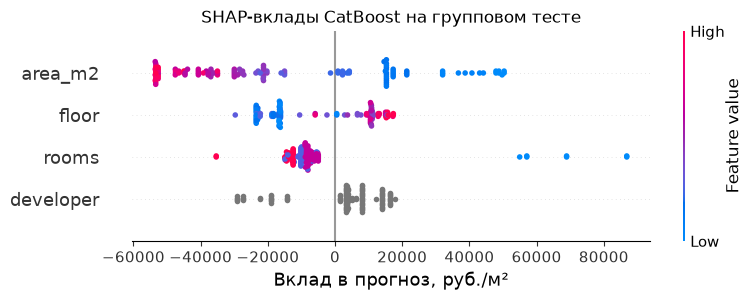

In [30]:
# Рассчитываем SHAP-значения
explainer = shap.TreeExplainer(group_catboost)
shap_values = explainer.shap_values(X_group)

# Сохраним значения для разбора вклада на отдельных объявлениях
group_shap = pd.DataFrame(
    shap_values,
    index=X_group.index,
    columns=X_group.columns,
)

# Строим Summary Plot
shap.summary_plot(shap_values, X_group, show=False, rng=SEED)
plt.title("SHAP-вклады CatBoost на групповом тесте")
plt.xlabel("Вклад в прогноз, руб./м²")
plt.tight_layout()
plt.show()

Площадь сильнее остальных признаков сдвигала прогнозы `CatBoost`:
для небольших квартир её вклад чаще был положительным, для больших -
отрицательным. У этажа картина обратная: низкие этажи чаще снижали
прогноз, высокие - повышали. Вклад комнатности у большинства объявлений
был отрицательным, но у отдельных квартир с низким значением `rooms`
он сильно повышал прогноз.

Площадь заняла первое место по среднему абсолютному SHAP-вкладу,
но её перемешивание снизило MAE на 11 334 руб./м². То есть модель
активно использовала площадь, однако на новых ЖК это не дало
выигрыша в точности по результатам проверки с перемешиванием.

## 8. Объявления с наибольшими отклонениями

Считаем отклонение как `100 × (факт / прогноз - 1)`.
Отрицательное значение означает, что цена предложения ниже прогноза,
положительное — выше. Это отклонение от модели, а не оценка
справедливой цены квартиры.

In [31]:
# Рассчитываем отклонение
group_results["deviation_pct"] = 100 * (
    group_results[TARGET] / group_results["prediction"] - 1
)

# Выводим десять объявлений
columns = [
    "developer", "project", "rooms", "area_m2", "floor", "finish",
    TARGET, "prediction", "deviation_pct", "source_url",
]

extremes = pd.concat([
    group_results.nsmallest(5, "deviation_pct"),
    group_results.nlargest(5, "deviation_pct"),
])[columns]

extremes.round({TARGET: 0, "prediction": 0, "deviation_pct": 1})

,developer,project,rooms,area_m2,floor,finish,asking_price_per_m2_rub,prediction,deviation_pct,source_url
235,ПИК,Восточное Бутово,2,56.3,17,NaN,213200,414333.0,-48.5,https://www.pik.ru/search/finish?metroStations...
34,ГК ФСК,Римский,2,57.6,5,Без отделки,227599,428711.0,-46.9,https://fsk.ru/moskva/living/kvartiry-bez-otdelki
39,ГК ФСК,Римский,2,63.8,10,Без отделки,223491,420901.0,-46.9,https://fsk.ru/moskva
40,ГК ФСК,Римский,2,63.4,11,Без отделки,224755,420901.0,-46.6,https://fsk.ru/moskva/living/kvartiry-bez-otdelki
41,ГК ФСК,Римский,2,63.4,12,Без отделки,225150,420901.0,-46.5,https://fsk.ru/moskva/living/kvartiry-bez-otdelki
66,ГК ФСК,Сидней Сити,2,46.5,7,Чистовая отделка,808435,433653.0,86.4,https://fsk.ru/moskva/2-komnatnye-kvartiry/eta...
70,ГК ФСК,Сидней Сити,1,39.1,8,Предчистовая отделка,795804,461667.0,72.4,https://fsk.ru/moskva/s-otdelkoj-rjadom-s-metr...
69,ГК ФСК,Сидней Сити,1,37.4,8,Предчистовая отделка,785097,461667.0,70.1,https://fsk.ru/moskva/s-otdelkoj-rjadom-s-metr...
501,Level Group,"Левел Мичуринский,этапы 3 и 4",4,91.5,37,NaN,658699,393544.0,67.4,https://level.ru/filter/4k-kvartiry-ot-level-g...
500,Level Group,"Левел Мичуринский,этапы 3 и 4",4,91.5,35,NaN,656759,393544.0,66.9,https://level.ru/filter/4k-kvartiry-ot-level-g...


### 8.1. Разбор трёх примеров

1. Восточное Бутово (ПИК), −48,5%. Модель спрогнозировала
   414 333 руб./м² при цене предложения 213 200 руб./м² -
   почти вдвое выше факта. Похожая ошибка наблюдается у четырёх
   двухкомнатных квартир в «Римском» от другого застройщика:
   их фактические цены - 223–228 тыс. руб./м², а прогнозы -
   421–429 тыс. руб./м². То есть модель завысила цену не только
   у одного объявления: она не воспроизвела низкий уровень цен
   в этих примерах из двух разных ЖК.

2. Сидней Сити (ГК ФСК), +86,4%. Цена двухкомнатной квартиры
   с чистовой отделкой - 808 435 руб./м², прогноз - 433 653 руб./м².
   Ещё две квартиры в том же ЖК, обе однокомнатные и с предчистовой
   отделкой, тоже оказались дороже прогноза более чем на 70%.
   Чистовая отделка могла повлиять на цену первой квартиры,
   но не объясняет общий промах по всем трём объявлениям.

3. Левел Мичуринский (Level Group), +67,4% и +66,9%.
   Две четырёхкомнатные квартиры площадью 91,5 м² на 35-м и 37-м
   этажах получили одинаковый прогноз - 393 544 руб./м². Их цены
   предложения тоже близки: 656 759 и 658 699 руб./м². Для этой
   пары важнее не то, что модель не различила этажи, а то, что она
   занизила общий уровень цены примерно на 264 тыс. руб./м².

### 8.2. SHAP для двух крайних отклонений

Разберём прогнозы для объявлений с самым отрицательным и самым
положительным отклонением. Базовое значение модели плюс вклады
четырёх признаков дают прогноз в руб./м². Положительный вклад
повышает прогноз относительно базового значения, отрицательный -
снижает.

In [32]:
# Выбираем объявления
cases = group_results.loc[[
    group_results["deviation_pct"].idxmin(),
    group_results["deviation_pct"].idxmax(),
]]

# Собираем и выводим таблицу
shap_table = group_shap.loc[cases.index].copy()
shap_table["Базовое значение"] = float(explainer.expected_value)
shap_table["Прогноз"] = cases["prediction"]
shap_table["Цена предложения"] = cases[TARGET]
shap_table.index = cases["project"]

shap_table.T.round(0).astype(int)

project,Восточное Бутово,Сидней Сити
developer,-19063,13971
rooms,-7365,-8913
area_m2,-27132,-16035
floor,6673,-16590
Базовое значение,461219,461219
Прогноз,414333,433653
Цена предложения,213200,808435


- **Восточное Бутово.** Сильнее всего прогноз снизили площадь
  (−27 132 руб./м²) и застройщик (−19 063 руб./м²). Этаж частично
  компенсировал это снижение (+6 673 руб./м²). Итоговый прогноз -
  414 333 руб./м², а цена предложения - 213 200 руб./м² (−48,5%
  относительно прогноза).
- **Сидней Сити.** Застройщик повысил прогноз (+13 971 руб./м²),
  но отрицательные вклады этажа (−16 590 руб./м²), площади
  (−16 035 руб./м²) и комнатности (−8 913 руб./м²) перевесили.
  Итоговый прогноз - 433 653 руб./м², а цена предложения -
  808 435 руб./м² (+86,4% относительно прогноза).

В обоих случаях модель дала прогноз ниже базового значения
(461 219 руб./м²), хотя отклонения цены предложения от прогноза
направлены в разные стороны. SHAP показывает, как признаки
сдвинули прогноз, но не объясняет причину ошибки модели.